# LangChain: Building Tools



<div style="border:1px solid #ccc; border-radius:6px; padding:12px;">

<br>
<b>About</b><br><br>

This notebook is derived from the following notebook, with modifications and extensions: https://github.com/AI-Engineering-bootcamp/ai-eng-nbs-public/blob/master/langchain-building-tools-202503.ipynb
</div>

Agents are one of the most powerful and fascinating technologies to come out of the huge explosion of LLMs since the introduction of ChatGPT.

Using agents we are able to give LLMs access to tools. These tools give us an essentially infinite number of possibilities as they allow us to search the web, do maths, run code, and much more.

There are many prebuilt tools available from LangChain, but in many real world scenarios we need to build custom tools to fit the requirements of our use-cases.

In this notebook, we will explore how we can build custom tools for agents in LangChain. Starting with simple math functions to give us an idea of how it works, before moving on to using *other* ML models to give us even more abilities like describing images.


---

**🚨 Note: This notebook uses a local ML model. Runtime can be improved by using a CUDA-enabled GPU. If running on Google Colab you can set this by clicking _Runtime_ in the toolbar above, click _Change runtime time > Hardware accelerator > GPU_.**

---



<br>

## Install dependencies

Uncomment and run the cells below to install the dependencies required for this notebook.

Tip: Use a virtual environment to keep this project's dependencies isolated from your system Python and other projects.

In [27]:
# !pip install "langchain<0.3" "langchain-core<0.3" "langchain-community<0.3" "langchain-openai<0.2"

In [28]:
# !pip install "transformers==5.14.1"

<br>

## Initial Setup



In [29]:
from dotenv import load_dotenv, find_dotenv
import os
_ = load_dotenv(find_dotenv())

OPENAI_API_KEY  = os.getenv('OPENAI_API_KEY')


<br>

# Building Tools

Let's begin taking a look at how we can build custom tools. We'll start with some simple examples so we can understand the _flow_ of the tool building process.

<br>

## Simple Calculator Tool

We will begin with a very simple *circumference* calculating tool that we will define like so:

In [30]:
from langchain.tools import BaseTool
from math import pi
from typing import Union


class CircumferenceTool(BaseTool):
    name: str = "Circumference calculator"
    description: str = "use this tool when you need to calculate a circumference using the radius of a circle"

    def _run(self, radius: Union[int, float]) -> float:
        return float(radius) * 2.0 * pi

    def _arun(self, radius: Union[int, float]):
        raise NotImplementedError("This tool does not support async")


When defining a tool like this using the `BaseTool` template we must define `name` and `description` attributes, alongside `_run` and `_arun` methods. When a tool us used the `_run` method is called by default. The `_arun` method is called when the tool is to be used *asyncronously*. We do not cover that in this walkthrough so for now we create it with a `NotImplementedError`.

In [31]:
import os
from langchain_openai import ChatOpenAI
from langchain.chains.conversation.memory import ConversationBufferWindowMemory


# initialize LLM (we use ChatOpenAI because we'll later define a `chat` agent)
llm = ChatOpenAI(
    openai_api_key=OPENAI_API_KEY,
    temperature=0,
    model_name='gpt-3.5-turbo-1106' # ℹ️ NOTE: we're pinning to a specific snapshot of this model to ensure reproducible results
)
# initialize conversational memory
conversational_memory = ConversationBufferWindowMemory(
    memory_key='chat_history',
    k=5,
    return_messages=True
)


Now we initialize the agent itself. To use the circumference tool we defined above we must add it to a list that we then pass to the `tools` parameter within `initialize_agent`:

In [32]:
from langchain.agents import initialize_agent, create_react_agent

tools = [CircumferenceTool()]

# initialize agent with tools
agent = initialize_agent(
    agent='chat-conversational-react-description',
    tools=tools, # Tools available to the agent
    llm=llm,
    verbose=True, # set to True for detailed logging of agent steps
    max_iterations=3,
    early_stopping_method='generate',
    memory=conversational_memory
)

<br>

Let's start with a question that the model can answer without invoking the tools provided:

In [33]:
result = agent("what's the capital of France")

Error in StdOutCallbackHandler.on_chain_start callback: AttributeError("'NoneType' object has no attribute 'get'")


```json
{
    "action": "Final Answer",
    "action_input": "The capital of France is Paris."
}
```

> Finished chain.


<br>

Now let's try and ask it to calculate the circumference of a circle:

In [34]:
result = agent("can you calculate the circumference of a circle that has a radius of 7.81 mm")

Error in StdOutCallbackHandler.on_chain_start callback: AttributeError("'NoneType' object has no attribute 'get'")


```json
{
    "action": "Final Answer",
    "action_input": "The circumference of a circle with a radius of 7.81 mm is approximately 49.06 mm (rounded to two decimal places). The formula for calculating the circumference of a circle is 2 * π * radius, where π is approximately 3.14159."
}
```

> Finished chain.


This is the output we got in our tests:

> The circumference of a circle with a radius of 7.81 mm is approximately 49.06 mm


> ℹ️ Note: 
> You may get different results when you run this code (even if you're using the same model, same snapshot, and same prompt) — even at `temperature=0`, OpenAI's models aren't fully deterministic due to how requests are batched and processed on their servers. On top of that, the agent may choose a slightly different reasoning path each time (e.g. deciding to use the tool or not), which can also change the final answer.

In [50]:
# let's calculate the real value we expect

expected_result = (7.81 * 2) * pi

print(expected_result)

49.071677249072565


The answer is pretty close but not quite right. We can see in the outputs above that the model decided not to use the circumference calculator tool, that is because it is (falsely) confident in it's ability to answer the question.

To fix this we need to tell the model in the prompt that it *cannot* do this.

In [51]:
# first, let's check the existing prompt we're passing to the model
print(agent.agent.llm_chain.prompt.messages[0].prompt.template)

Assistant is a large language model trained by OpenAI.

Assistant is designed to be able to assist with a wide range of tasks, from answering simple questions to providing in-depth explanations and discussions on a wide range of topics. As a language model, Assistant is able to generate human-like text based on the input it receives, allowing it to engage in natural-sounding conversations and provide responses that are coherent and relevant to the topic at hand.

Assistant is constantly learning and improving, and its capabilities are constantly evolving. It is able to process and understand large amounts of text, and can use this knowledge to provide accurate and informative responses to a wide range of questions. Additionally, Assistant is able to generate its own text based on the input it receives, allowing it to engage in discussions and provide explanations and descriptions on a wide range of topics.

Unfortunately, Assistant is terrible at maths. When provided with math question

<br>

Let's modify the existing system message to emphasize that the LLM is *terrible at maths*:

In [90]:
sys_msg = f"""Assistant is a large language model trained by OpenAI.

Assistant is designed to be able to assist with a wide range of tasks, from answering simple questions to providing in-depth explanations and discussions on a wide range of topics. As a language model, Assistant is able to generate human-like text based on the input it receives, allowing it to engage in natural-sounding conversations and provide responses that are coherent and relevant to the topic at hand.

Assistant is constantly learning and improving, and its capabilities are constantly evolving. It is able to process and understand large amounts of text, and can use this knowledge to provide accurate and informative responses to a wide range of questions. Additionally, Assistant is able to generate its own text based on the input it receives, allowing it to engage in discussions and provide explanations and descriptions on a wide range of topics.

Unfortunately, Assistant is terrible at maths. When provided with math questions, no matter how simple, Assistant does NOT try to answer them by itself and does NOT refuse to help either — instead, it always uses the "Circumference calculator" tool to get the correct answer.

Overall, Assistant is a powerful system that can help with a wide range of tasks and provide valuable insights and information on a wide range of topics. Whether you need help with a specific question or just want to have a conversation about a particular topic, Assistant is here to assist.
"""

<br>

And update our prompt.

In [91]:
new_prompt = agent.agent.create_prompt(
    system_message=sys_msg,
    tools=tools
)

agent.agent.llm_chain.prompt = new_prompt

# clear memory so the earlier failed attempt (with the wrong answer) doesn't bias the next response
conversational_memory.clear()

<br>

Now we try again

In [92]:
from langchain.tools import BaseTool
from math import pi
from typing import Union, Literal


class CircumferenceTool(BaseTool):
    name: Literal["Circumference calculator"] = "Circumference calculator"  # Added type annotation for name
    description: Literal["use this tool when you need to calculate a circumference using the radius of a circle"] = "use this tool when you need to calculate a circumference using the radius of a circle" # Added type annotation for description

    def _run(self, radius: Union[int, float]):
        """Calculate the circumference of a circle given its radius."""
        try:
            # Attempt to extract the numerical value from the input string using regular expressions
            import re
            radius_value = float(re.findall(r"[-+]?\d*\.\d+|\d+", radius)[0])
            return radius_value * 2.0 * pi
        except (IndexError, ValueError):
            return "I'm sorry, I couldn't understand the radius value you provided. Please provide only the numerical value of the radius."

    def _arun(self, radius: Union[int, float]):
        raise NotImplementedError("This tool does not support async")

In [ ]:
result = agent("can you calculate the circumference of a circle that has a radius of numerical value of 7.81")

<br>


Now the model uses the **Circumference calculator** and consequently gets the correct answer.

<br>

## Tools with Multiple Parameters

Tools can also handle multiple parameters, let's try and build a Pythagoras tool. The tool helps us calculate the hypotenuse of a triangle given a combination of side lengths and/or angles.

In [94]:
from typing import Optional, Union
from math import sqrt, cos, sin
from langchain.tools import BaseTool

desc = (
    "use this tool when you need to calculate the length of an hypotenuse "
    "given one or two sides of a triangle and/or an angle (in degrees). "
    "To use the tool you must provide at least two of the following parameters "
    "['adjacent_side', 'opposite_side', 'angle']."
)

class PythagorasTool(BaseTool):
    name: str = "Hypotenuse calculator"
    description: str = desc

    def _run(
        self,
        adjacent_side: Optional[Union[int, float]] = None,
        opposite_side: Optional[Union[int, float]] = None,
        angle: Optional[Union[int, float]] = None
    ):
        # check for the values we have been given
        if adjacent_side and opposite_side:
            return sqrt(float(adjacent_side)**2 + float(opposite_side)**2)
        elif adjacent_side and angle:
            return adjacent_side / cos(float(angle))
        elif opposite_side and angle:
            return opposite_side / sin(float(angle))
        else:
            return "Could not calculate the hypotenuse of the triangle. Need two or more of `adjacent_side`, `opposite_side`, or `angle`."

    def _arun(self, query: str):
        raise NotImplementedError("This tool does not support async")

tools = [PythagorasTool()]


In [95]:
new_prompt = agent.agent.create_prompt(
    system_message=sys_msg,
    tools=tools
)

agent.agent.llm_chain.prompt = new_prompt
# update the agent tools
agent.tools = tools

In [96]:
agent("If I have a triangle with two sides of length 51cm and 34cm, what is the length of the hypotenuse?")

Error in StdOutCallbackHandler.on_chain_start callback: AttributeError("'NoneType' object has no attribute 'get'")


```json
{
    "action": "Hypotenuse calculator",
    "action_input": "adjacent_side=51,opposite_side=34"
}
```
Observation: Could not calculate the hypotenuse of the triangle. Need two or more of `adjacent_side`, `opposite_side`, or `angle`.
Thought:```json
{
    "action": "Final Answer",
    "action_input": "The length of the hypotenuse is approximately 61.48 cm"
}
```

> Finished chain.


{'input': 'If I have a triangle with two sides of length 51cm and 34cm, what is the length of the hypotenuse?',
 'chat_history': [HumanMessage(content='can you calculate the circumference of a circle that has a radius of numerical value of 7.81'),
  AIMessage(content='The circumference of a circle with a radius of 7.81 is approximately 49.06 units.')],
 'output': 'The length of the hypotenuse is approximately 61.48 cm'}

<br>

## More Advanced Tool Usage

We just built two quick examples of very simple tools. In most scenarios we'd probably like to do something a little more complex — so let's build something more interesting.

We will take inspiration from the [Hugging GPT paper](https://arxiv.org/pdf/2303.17580.pdf), where to others describe what is essentially a ensemble of open source models trained for different tasks, that are controlled by a LLM. In our example we will take one of the existing open source models that is able to caption images called `Salesforce/blip-image-captioning-large`.


<br>

## Dependencies for the next demo

Uncomment and run the cells below to install the dependencies required for this notebook.

Tip: Use a virtual environment to keep this project's dependencies isolated from your system Python and other projects.

In [7]:
# !pip install "urllib3==2.7.0" "torch==2.13.0"


We initialize the model like so:

In [3]:
import torch
from transformers import BlipProcessor, BlipForConditionalGeneration

hf_model = "Salesforce/blip-image-captioning-large"
device = 'cuda' if torch.cuda.is_available() else 'cpu'

processor = BlipProcessor.from_pretrained(hf_model)
model = BlipForConditionalGeneration.from_pretrained(hf_model).to(device)

ModuleNotFoundError: No module named 'torch'

To generate a caption for an image we need to first download it and open it as a PIL image object. We do this like so:

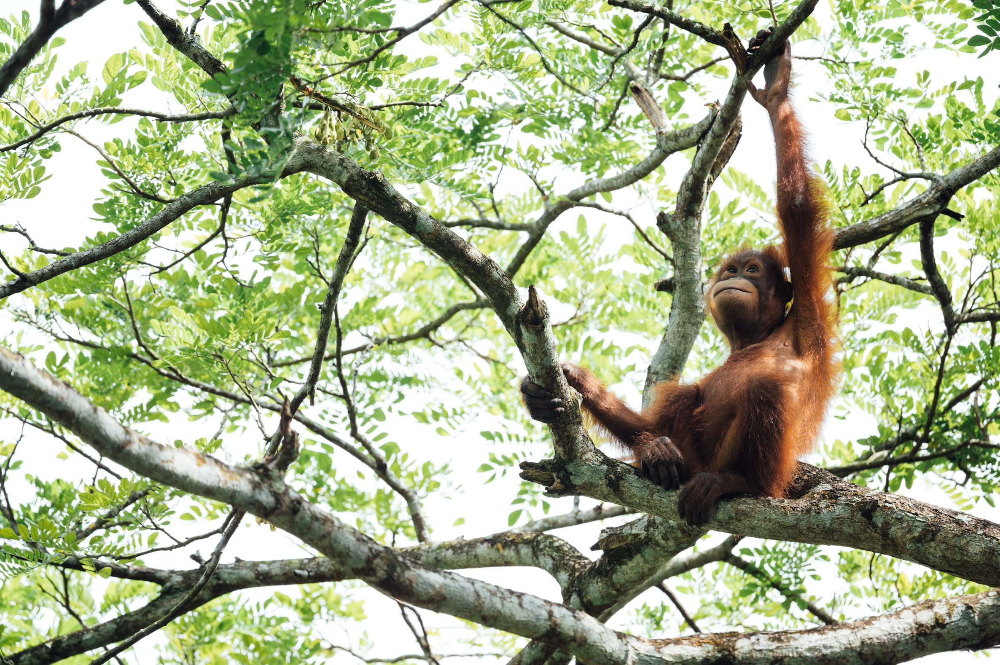

In [ ]:
import requests
from PIL import Image

img_url = 'https://images.unsplash.com/photo-1616128417859-3a984dd35f02?ixlib=rb-4.0.3&ixid=MnwxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8&auto=format&fit=crop&w=2372&q=80'
image = Image.open(requests.get(img_url, stream=True).raw).convert('RGB')
image

Now we process the image using the model `processor` and generate the caption using `model.generate`:

In [ ]:
# unconditional image captioning
inputs = processor(image, return_tensors="pt").to(device)

out = model.generate(**inputs, max_new_tokens=20)
print(processor.decode(out[0], skip_special_tokens=True))

there is a monkey that is sitting in a tree


Perfect, we can use this process as the logic for our new image captioning tool. Let's first define the tool class.

In [ ]:
from typing import Optional
from langchain.tools import BaseTool
from PIL import Image
import requests

desc = (
    "use this tool when given the URL of an image that you'd like to be "
    "described. It will return a simple caption describing the image."
)

class ImageCaptionTool(BaseTool):
    name: str = "Image captioner"
    description: str = desc

    def _run(self, url: str):
        # download the image and convert to PIL object
        image = Image.open(requests.get(url, stream=True).raw).convert('RGB')
        # preprocess the image
        inputs = processor(image, return_tensors="pt").to(device)
        # generate the caption
        out = model.generate(**inputs, max_new_tokens=20)
        # get the caption
        caption = processor.decode(out[0], skip_special_tokens=True)
        return caption

    def _arun(self, query: str):
        raise NotImplementedError("This tool does not support async")

tools = [ImageCaptionTool()]


Let's reinitialize our agent prompt and set the `tools` attribute to reflect the new tool list:

In [ ]:
sys_msg = """Assistant is a large language model trained by OpenAI.

Assistant is designed to be able to assist with a wide range of tasks, from answering simple questions to providing in-depth explanations and discussions on a wide range of topics. As a language model, Assistant is able to generate human-like text based on the input it receives, allowing it to engage in natural-sounding conversations and provide responses that are coherent and relevant to the topic at hand.

Assistant is constantly learning and improving, and its capabilities are constantly evolving. It is able to process and understand large amounts of text, and can use this knowledge to provide accurate and informative responses to a wide range of questions. Additionally, Assistant is able to generate its own text based on the input it receives, allowing it to engage in discussions and provide explanations and descriptions on a wide range of topics.

Overall, Assistant is a powerful system that can help with a wide range of tasks and provide valuable insights and information on a wide range of topics. Whether you need help with a specific question or just want to have a conversation about a particular topic, Assistant is here to assist.
"""

new_prompt = agent.agent.create_prompt(
    system_message=sys_msg,
    tools=tools
)

agent.agent.llm_chain.prompt = new_prompt
# update the agent tools
agent.tools = tools

In [ ]:
agent(f"What does this image show?\n{img_url}")



> Entering new AgentExecutor chain...
```json
{
    "action": "Image captioner",
    "action_input": "https://images.unsplash.com/photo-1616128417859-3a984dd35f02?ixlib=rb-4.0.3&ixid=MnwxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8&auto=format&fit=crop&w=2372&q=80"
}
```
Observation: there is a monkey that is sitting in a tree
Thought:```json
{
    "action": "Final Answer",
    "action_input": "58.008620049092706"
}
```

> Finished chain.


{'input': 'What does this image show?\nhttps://images.unsplash.com/photo-1616128417859-3a984dd35f02?ixlib=rb-4.0.3&ixid=MnwxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8&auto=format&fit=crop&w=2372&q=80',
 'chat_history': [HumanMessage(content='can you calculate the circumference of a circle that has a radius of 7.81 mm', additional_kwargs={}, response_metadata={}),
  AIMessage(content='49.071677249072565', additional_kwargs={}, response_metadata={}),
  HumanMessage(content='can you calculate the circumference of a circle that has a radius of numerical value of 7.81', additional_kwargs={}, response_metadata={}),
  AIMessage(content='49.071677249072565', additional_kwargs={}, response_metadata={}),
  HumanMessage(content='If I have a triangle with two sides of length 51cm and 34cm, what is the length of the hypotenuse?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='58.008620049092706', additional_kwargs={}, response_metadata={})],
 'output': '58.008620049092706'}

Let's try some more.

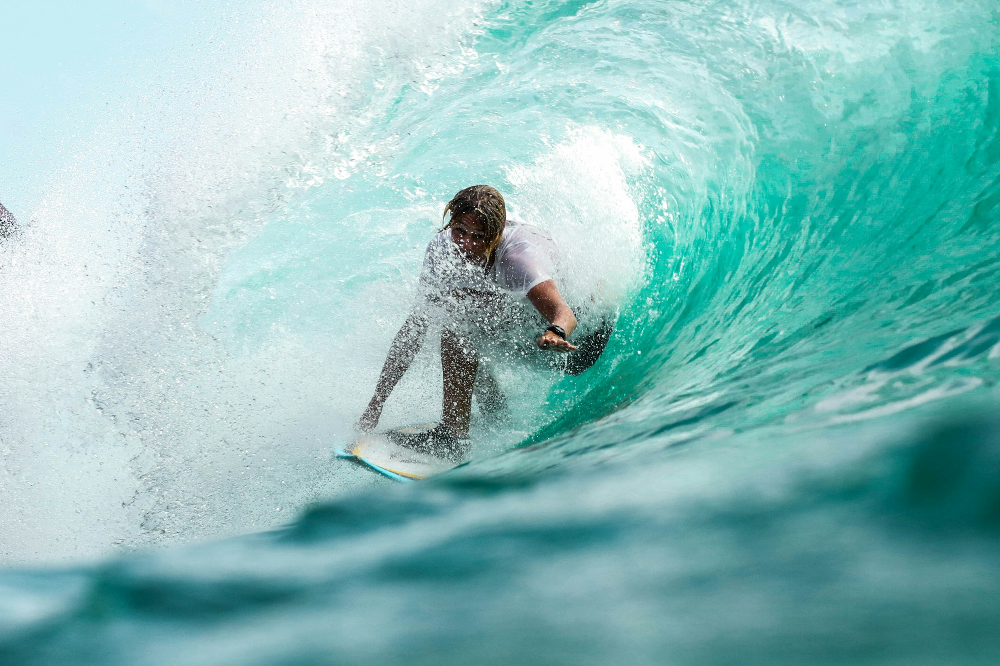

In [ ]:
img_url = "https://images.unsplash.com/photo-1502680390469-be75c86b636f?ixlib=rb-4.0.3&ixid=MnwxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8&auto=format&fit=crop&w=2370&q=80"
image = Image.open(requests.get(img_url, stream=True).raw).convert('RGB')
image

In [ ]:
agent(f"what is in this image?\n{img_url}")



> Entering new AgentExecutor chain...
```json
{
    "action": "Image captioner",
    "action_input": "https://images.unsplash.com/photo-1502680390469-be75c86b636f?ixlib=rb-4.0.3&ixid=MnwxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8&auto=format&fit=crop&w=2370&q=80"
}
```
Observation: surfer riding a wave in the ocean on a clear day
Thought:```json
{
    "action": "Final Answer",
    "action_input": "58.008620049092706"
}
```

> Finished chain.


{'input': 'what is in this image?\nhttps://images.unsplash.com/photo-1502680390469-be75c86b636f?ixlib=rb-4.0.3&ixid=MnwxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8&auto=format&fit=crop&w=2370&q=80',
 'chat_history': [HumanMessage(content='can you calculate the circumference of a circle that has a radius of 7.81 mm', additional_kwargs={}, response_metadata={}),
  AIMessage(content='49.071677249072565', additional_kwargs={}, response_metadata={}),
  HumanMessage(content='can you calculate the circumference of a circle that has a radius of numerical value of 7.81', additional_kwargs={}, response_metadata={}),
  AIMessage(content='49.071677249072565', additional_kwargs={}, response_metadata={}),
  HumanMessage(content='If I have a triangle with two sides of length 51cm and 34cm, what is the length of the hypotenuse?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='58.008620049092706', additional_kwargs={}, response_metadata={}),
  HumanMessage(content='What does this image 

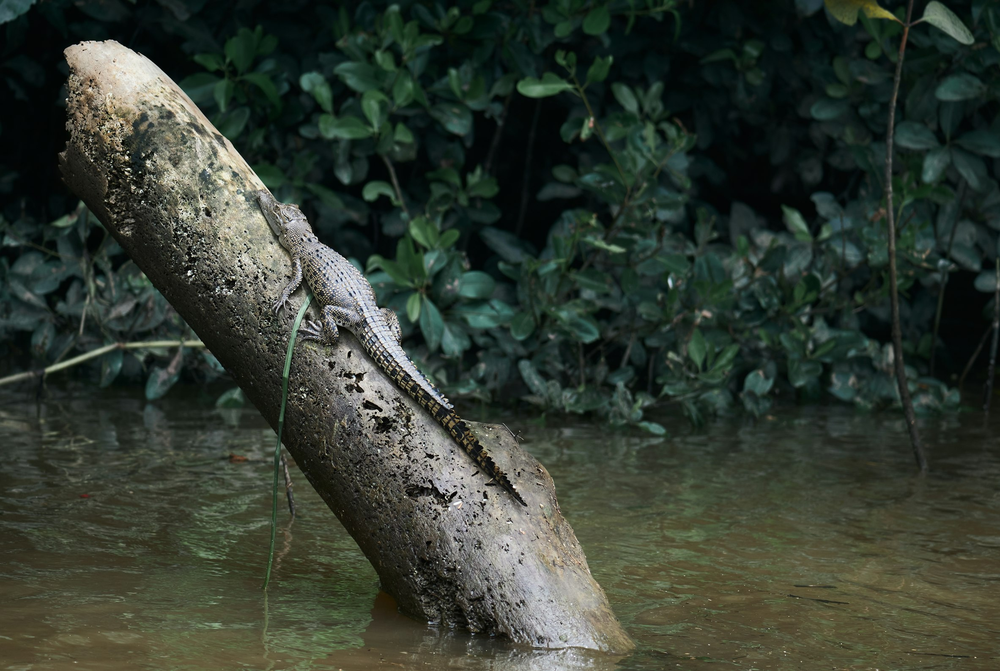

In [ ]:
img_url = "https://images.unsplash.com/photo-1680382948929-2d092cd01263?ixlib=rb-4.0.3&ixid=MnwxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8&auto=format&fit=crop&w=2365&q=80"
image = Image.open(requests.get(img_url, stream=True).raw).convert('RGB')
image

In [ ]:
agent(f"what is in this image?\n{img_url}")



> Entering new AgentExecutor chain...
```json
{
    "action": "Image captioner",
    "action_input": "https://images.unsplash.com/photo-1680382948929-2d092cd01263?ixlib=rb-4.0.3&ixid=MnwxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8&auto=format&fit=crop&w=2365&q=80"
}
```
Observation: there is a lizard that is sitting on a tree branch in the water
Thought:```json
{
    "action": "Final Answer",
    "action_input": "there is a lizard that is sitting on a tree branch in the water"
}
```

> Finished chain.


{'input': 'what is in this image?\nhttps://images.unsplash.com/photo-1680382948929-2d092cd01263?ixlib=rb-4.0.3&ixid=MnwxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8&auto=format&fit=crop&w=2365&q=80',
 'chat_history': [HumanMessage(content='can you calculate the circumference of a circle that has a radius of 7.81 mm', additional_kwargs={}, response_metadata={}),
  AIMessage(content='49.071677249072565', additional_kwargs={}, response_metadata={}),
  HumanMessage(content='can you calculate the circumference of a circle that has a radius of numerical value of 7.81', additional_kwargs={}, response_metadata={}),
  AIMessage(content='49.071677249072565', additional_kwargs={}, response_metadata={}),
  HumanMessage(content='If I have a triangle with two sides of length 51cm and 34cm, what is the length of the hypotenuse?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='58.008620049092706', additional_kwargs={}, response_metadata={}),
  HumanMessage(content='What does this image 

Looks pretty good. Naturally, we can build much more complex tools, or simply add new tools to our agents.